# Fase 3 · Búsqueda y selección de hiperparámetros

**Detección de exoplanetas en Kepler con una red multirrama — iteración 2** (más datos, entrenamiento en GPU)

Curso de Deep Learning · Especialización en Inteligencia Artificial · Universidad Nacional de Colombia

**Autores:** Thomas Monnier Granda, Esteban Felipe Genes Noya, Juan Sebastian Higuita Riascos, Alexandra Arias Mazo y Eliel Segura Perez

> **Pregunta de este cuaderno:** ¿las redes del protocolo eran las mejores posibles, y cómo se elige sin hacer trampa?

Este cuaderno no entrena nada: lee las evidencias que dejaron los pasos 1 a 5 (`iteracion_2/*.bat`) y las explica. Cada cifra sale de un archivo del repositorio.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

import apoyo  # iteracion_2/notebooks/apoyo.py: rutas, lectura de evidencias y figuras

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 80)
apoyo.estilo()
print("Raíz del repositorio:", apoyo.RAIZ.name, "| evidencias en", apoyo.EVIDENCIAS.relative_to(apoyo.RAIZ))

Raíz del repositorio: Proyecto_Final | evidencias en iteracion_2/evidencias


## 1. Las reglas de la búsqueda

1. **El espacio se declara antes de entrenar** (`src/temporal/busqueda_it2.py`) y no se cambia al ver resultados.
2. **12 configuraciones por red**, las mismas para todas: la del protocolo (configuración 0) y 11 sorteadas con semilla fija.
3. **Selección anidada:** cada partición elige su configuración mirando solo su validación interna. La prueba nunca decide.
4. **Criterio:** la menor NLL de validación. La NLL (pérdida logarítmica) premia a la vez ordenar bien y dar probabilidades honestas.

Se buscó sobre el tamaño de la red (ancho, bloques extra), la activación, la normalización, la pérdida
(entropía cruzada o con suavizado de etiquetas), la tasa de aprendizaje, la regularización y el tamaño de lote.

In [2]:
red = "m2_promedio"   # cambia por: m4_escalares, m1_astronet, m2_atencion, m2_gru
cfg = apoyo.configuraciones(red)
columnas = [c for c in cfg.columns if not c.startswith("nll_val_k")]
display(Markdown(f"**{apoyo.REDES[red]}** — las 12 configuraciones (la 00 es el protocolo)"))
display(cfg[columnas].set_index("configuracion"))

**Rama 2 · promedio** — las 12 configuraciones (la 00 es el protocolo)

,tasa_aprendizaje,weight_decay,lote,perdida,activacion,capas_extra,dropout,ancho,normalizacion,parametros,epocas_medias,nll_val_media,auc_prueba,nll_prueba
configuracion,,,,,,,,,,,,,,
cfg00,0.001000,0.00010,128,ce,relu,0,0.3,1.0,NaN,5027,88.2,0.4921,0.9356,0.4937
cfg01,0.000796,0.00100,256,suavizado,relu,0,0.5,2.0,NaN,13859,51.0,0.6133,0.9191,0.6163
cfg02,0.000309,0.00010,256,ce,relu,0,0.3,2.0,NaN,13859,126.8,0.5222,0.9269,0.5248
cfg03,0.000341,0.00000,128,suavizado,tanh,0,0.5,2.0,NaN,13859,99.0,0.5696,0.9191,0.5729
cfg04,0.000448,0.00001,256,suavizado,relu,0,0.5,4.0,capa,47267,54.6,0.6089,0.9227,0.6092
cfg05,0.001760,0.00100,256,ce,tanh,1,0.5,4.0,capa,215971,68.4,0.4648,0.9325,0.4703
cfg06,0.000391,0.00000,256,ce,relu,1,0.3,1.0,capa,16579,105.0,0.4634,0.9371,0.4724
cfg07,0.000969,0.00000,128,ce,tanh,0,0.1,1.0,NaN,5027,127.6,0.4582,0.9427,0.4629
cfg08,0.004260,0.00001,128,ce,relu,0,0.5,2.0,NaN,13859,21.6,0.6102,0.9086,0.6152


## 2. ¿Sirvió buscar?

Para cada red se compara, sobre la prueba, el protocolo fijo con el sistema "con búsqueda" (cada
partición con su configuración elegida). La diferencia es **pareada**: los mismos ejemplos, remuestreados
por estrella 2.000 veces. Una diferencia es *distinguible* si su intervalo del 95 % no contiene el cero.

,AUC protocolo fijo,AUC con búsqueda,diferencia,¿distinguible?,elegida por partición
red,,,,,
Rama 4 · escalares,0.9795 [0.9751; 0.9836],0.9830 [0.9794; 0.9863],+0.0034 [+0.0017; +0.0054],sí,cfg05 cfg06 cfg01 cfg05 cfg01
Rama 1 · vistas plegadas,0.9513 [0.9454; 0.9573],0.9518 [0.9458; 0.9578],+0.0004 [-0.0014; +0.0024],no,cfg00 cfg00 cfg01 cfg00 cfg00
Rama 2 · promedio,0.9356 [0.9281; 0.9424],0.9436 [0.9369; 0.9497],+0.0080 [+0.0041; +0.0120],sí,cfg10 cfg10 cfg10 cfg10 cfg10
Rama 2 · atención,0.9377 [0.9310; 0.9443],0.9421 [0.9356; 0.9483],+0.0044 [+0.0005; +0.0086],sí,cfg07 cfg11 cfg07 cfg00 cfg07
Rama 2 · GRU,0.9403 [0.9334; 0.9465],0.9399 [0.9331; 0.9461],-0.0004 [-0.0026; +0.0018],no,cfg00 cfg00 cfg06 cfg00 cfg00


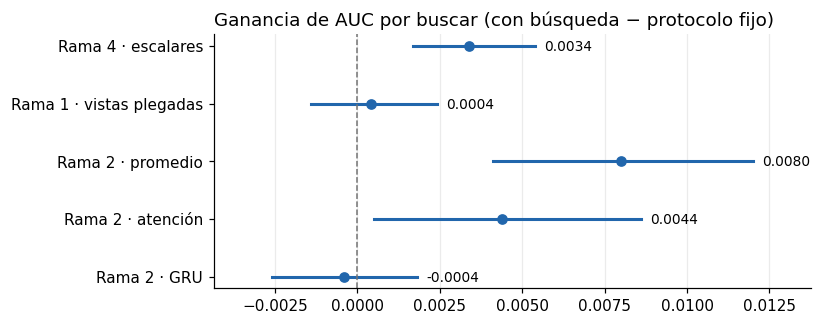

In [3]:
display(apoyo.tabla_busqueda())
fig, eje = plt.subplots(figsize=(7, 3))
apoyo.bosque({r: apoyo.resumen_busqueda(r)["auc_prueba"]["diferencia"] for r in apoyo.REDES},
             "Ganancia de AUC por buscar (con búsqueda − protocolo fijo)", referencia=0.0, eje=eje)
apoyo.guardar(fig, "03_ganancia_busqueda")

**Lectura.** Tres de las cinco redes mejoran de forma distinguible, todas por milésimas. La rama 1 y
la GRU se quedan casi siempre con la red del protocolo. La búsqueda ayuda, pero poco.

## 3. ¿Las redes grandes ganan?

Cada punto es una configuración: su tamaño frente a su NLL de validación (menor es mejor).

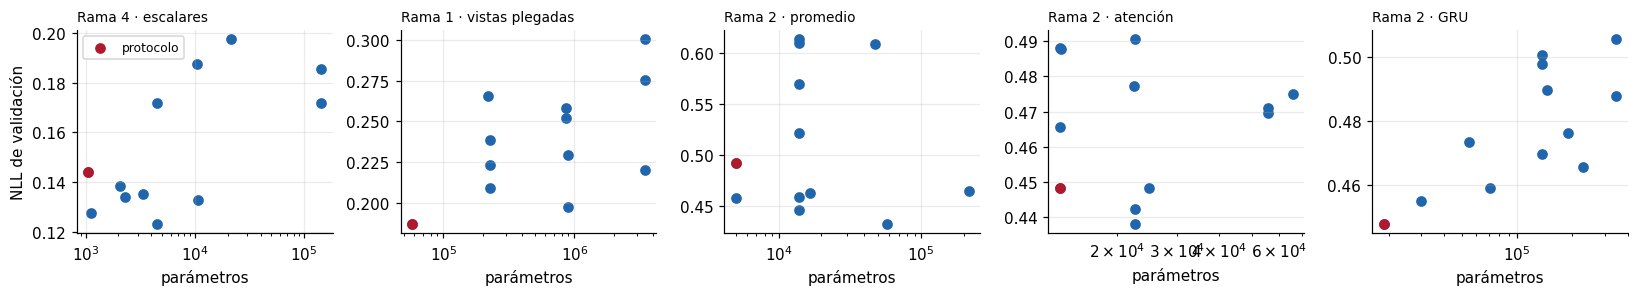

In [4]:
fig, ejes = plt.subplots(1, 5, figsize=(15, 2.8), sharey=False)
for eje, (red, nombre) in zip(ejes, apoyo.REDES.items()):
    cfg = apoyo.configuraciones(red)
    eje.scatter(cfg["parametros"], cfg["nll_val_media"], color="#2166ac")
    eje.scatter(cfg.loc[0, "parametros"], cfg.loc[0, "nll_val_media"], color="#b2182b", label="protocolo", zorder=3)
    eje.set_xscale("log"); eje.set_title(nombre, loc="left", fontsize=9); eje.set_xlabel("parámetros")
ejes[0].set_ylabel("NLL de validación"); ejes[0].legend(fontsize=8)
fig.tight_layout(); apoyo.guardar(fig, "03_tamano_vs_nll")

Solo en la rama 2 con promedio gana con claridad una red mayor (el doble de ancha y un bloque más).
En las demás, crecer no garantiza mejorar: las redes más grandes de la rama 1 y de la rama 4 quedan peor.

## 4. Análisis de sensibilidad (exploratorio): ¿y si se eligiera por AUC?

La NLL castiga al suavizado de etiquetas, que baja la confianza a propósito. Para saber si la conclusión
depende del criterio, se repitió la selección usando el AUC de validación. **Este análisis se añadió
después de ver resultados, así que no reemplaza al principal:** solo informa.

In [5]:
filas = []
for red, nombre in apoyo.REDES.items():
    s = apoyo.sensibilidad(red)
    filas.append({"red": nombre,
                  "AUC eligiendo por NLL": s["auc_prueba"]["seleccion_por_nll"]["estimacion"],
                  "AUC eligiendo por AUC": s["auc_prueba"]["seleccion_por_auc"]["estimacion"],
                  "diferencia de AUC": apoyo.con_intervalo(s["auc_prueba"]["auc_menos_nll"], signo=True),
                  "diferencia de NLL": apoyo.con_intervalo(s["nll_prueba"]["auc_menos_nll"], signo=True),
                  "particiones con la misma elección": f"{s['particiones_con_la_misma_eleccion']} de 5"})
display(pd.DataFrame(filas).set_index("red"))

,AUC eligiendo por NLL,AUC eligiendo por AUC,diferencia de AUC,diferencia de NLL,particiones con la misma elección
red,,,,,
Rama 4 · escalares,0.9830,0.9826,-0.0004 [-0.0010; +0.0001],+0.0025 [+0.0007; +0.0046],4 de 5
Rama 1 · vistas plegadas,0.9518,0.9575,+0.0058 [+0.0011; +0.0102],+0.0308 [+0.0214; +0.0403],0 de 5
Rama 2 · promedio,0.9436,0.9473,+0.0037 [-0.0002; +0.0079],+0.0242 [+0.0169; +0.0317],0 de 5
Rama 2 · atención,0.9421,0.9422,+0.0002 [-0.0030; +0.0031],+0.0014 [-0.0052; +0.0078],2 de 5
Rama 2 · GRU,0.9399,0.9381,-0.0018 [-0.0045; +0.0010],+0.0097 [+0.0047; +0.0148],3 de 5


**Lectura.** No hay un ganador uniforme. Solo en la rama 1 elegir por AUC discrimina mejor, y lo paga
con peor calibración. En las otras cuatro redes, elegir por AUC no mejora el AUC y en varias empeora
la NLL. Se mantiene la NLL como criterio principal; el cuaderno 5 muestra que a nivel de sistema
tampoco conviene cambiarlo.

## 5. Una adaptación que sí se hizo, y por qué es legítima

En la rama 2 la profundidad se limitó a un bloque extra (no dos). Se decidió **antes de entrenar esa
rama**, por coste: una prueba con datos aleatorios midió horas por partición para la combinación mayor.
El motivo no dependió de ningún resultado; queda documentado en el código y en el historial.